# Wettervergleich: Berlin 2024–2026

Dieses Notebook vergleicht tägliche Wetterbeobachtungen des Deutschen Wetterdienstes (DWD) für die Station **Berlin-Tempelhof (00433)**. Die Daten stammen aus dem [DWD Climate Data Center](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/).

Verglichen wird jeweils der Zeitraum vom 1. Januar bis zum letzten beim DWD verfügbaren Datum des Jahres 2026. 2026 ist also ein laufendes Jahr. Das Notebook zeigt Kennzahlen für diesen gemeinsamen Zeitraum sowie Monatsverläufe; im Diagramm werden nur vollständig vorliegende Monate berücksichtigt.

Für den Download ist eine Internetverbindung erforderlich. Die Diagramme verwenden `matplotlib`; falls nötig, installiere es in einer Codezelle mit `%pip install matplotlib`.

In [6]:
import csv
import io
import re
from calendar import monthrange
from collections import defaultdict
from datetime import date, datetime
from statistics import mean
from urllib.request import Request, urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt

station_id = "00433"
station_name = "Berlin-Tempelhof"
jahre = (2024, 2025, 2026)
dwd_basis = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl"

## 1. DWD-Tagesdaten laden

Der DWD stellt Stationsdaten als ZIP-Dateien mit Semikolon-getrennten Tabellen bereit. Wir kombinieren den historischen und den aktuellen Datensatz; bei überlappenden Tagen gilt der aktuelle Datensatz. `TMK`, `TXK`, `TNK` und `RSK` stehen für Tagesmittel-, Höchst- und Tiefsttemperatur sowie Niederschlag.

In [7]:
historisch_verzeichnis = f"{dwd_basis}/historical/"
aktuell_url = f"{dwd_basis}/recent/tageswerte_KL_{station_id}_akt.zip"

anfrage = Request(historisch_verzeichnis, headers={"User-Agent": "Mozilla/5.0"})
with urlopen(anfrage, timeout=30) as antwort:
    verzeichnis = antwort.read().decode("utf-8", errors="replace")

historische_datei = next(
    name for name in re.findall(r'href="([^"]+)"', verzeichnis)
    if name.startswith(f"tageswerte_KL_{station_id}_") and name.endswith("_hist.zip")
)
historisch_url = historisch_verzeichnis + historische_datei


def parse_dwd_wert(text):
    wert = float(text)
    return None if wert <= -999 else wert


def lade_dwd_daten(url):
    anfrage = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urlopen(anfrage, timeout=90) as antwort:
        archiv_bytes = antwort.read()

    with ZipFile(io.BytesIO(archiv_bytes)) as archiv:
        tabellenname = next(
            name for name in archiv.namelist()
            if name.startswith("produkt_klima_tag_") and name.endswith(".txt")
        )
        tabellentext = archiv.read(tabellenname).decode("latin-1")

    messwerte = []
    for zeile in csv.DictReader(io.StringIO(tabellentext), delimiter=";"):
        zeile = {schluessel.strip(): wert.strip() for schluessel, wert in zeile.items() if schluessel}
        datum = datetime.strptime(zeile["MESS_DATUM"], "%Y%m%d").date()
        if datum.year not in jahre:
            continue
        messwerte.append({
            "datum": datum,
            "mittel": parse_dwd_wert(zeile["TMK"]),
            "maximum": parse_dwd_wert(zeile["TXK"]),
            "minimum": parse_dwd_wert(zeile["TNK"]),
            "niederschlag": parse_dwd_wert(zeile["RSK"]),
        })
    return messwerte


messwerte_nach_datum = {}
for quelle in (historisch_url, aktuell_url):
    for messwert in lade_dwd_daten(quelle):
        messwerte_nach_datum[messwert["datum"]] = messwert

daten = sorted(messwerte_nach_datum.values(), key=lambda eintrag: eintrag["datum"])
print(f"Station: {station_name} (DWD {station_id})")
print(f"{len(daten)} Tagesdatensätze: {daten[0]['datum']} bis {daten[-1]['datum']}")
print(f"Letzter verfügbarer Tag 2026: {max(eintrag['datum'] for eintrag in daten if eintrag['datum'].year == 2026)}")

Station: Berlin-Tempelhof (DWD 00433)
1036 Tagesdatensätze: 2024-01-01 bis 2026-11-01
Letzter verfügbarer Tag 2026: 2026-11-01


## 2. Jahre fair vergleichen

Die Kennzahlen vergleichen für alle drei Jahre den Zeitraum vom 1. Januar bis zum gleichen Monat und Tag wie der letzte DWD-Messwert von 2026. 2026 ist damit ein Zwischenstand, kein Jahreswert. Die Spalte „Tage“ macht sichtbar, dass ein Schaltjahr einen zusätzlichen Tag enthalten kann. Fehlende DWD-Werte werden bei der jeweiligen Kennzahl ausgelassen.

In [8]:
letzter_2026_tag = max(
    eintrag["datum"] for eintrag in daten if eintrag["datum"].year == 2026
)
vergleich = {}

for jahr in jahre:
    stichtag = date(jahr, letzter_2026_tag.month, letzter_2026_tag.day)
    zeitraum = [
        eintrag for eintrag in daten
        if eintrag["datum"].year == jahr and eintrag["datum"] <= stichtag
    ]
    vergleich[jahr] = zeitraum

print(f"Vergleichszeitraum: 1. Januar bis {letzter_2026_tag:%d.%m.} jedes Jahres")
print("Jahr | Tage | Mitteltemperatur | Niederschlag | Warme Tage | Frosttage")
print("     |      |       (°C)       |     (mm)     | TXK >= 25 °C | TNK < 0 °C")

for jahr, zeitraum in vergleich.items():
    temperaturen = [eintrag["mittel"] for eintrag in zeitraum if eintrag["mittel"] is not None]
    niederschlag = [eintrag["niederschlag"] for eintrag in zeitraum if eintrag["niederschlag"] is not None]
    warme_tage = sum(
        eintrag["maximum"] is not None and eintrag["maximum"] >= 25
        for eintrag in zeitraum
    )
    frosttage = sum(
        eintrag["minimum"] is not None and eintrag["minimum"] < 0
        for eintrag in zeitraum
    )
    print(
        f"{jahr} | {len(zeitraum):4} | {mean(temperaturen):15.1f} | "
        f"{sum(niederschlag):11.1f} | {warme_tage:12} | {frosttage:9}"
    )

Vergleichszeitraum: 1. Januar bis 01.11. jedes Jahres
Jahr | Tage | Mitteltemperatur | Niederschlag | Warme Tage | Frosttage
     |      |       (°C)       |     (mm)     | TXK >= 25 °C | TNK < 0 °C
2024 |  306 |            13.8 |       463.8 |           74 |        29
2025 |  305 |            12.4 |       407.0 |           51 |        40
2026 |  305 |            12.2 |       325.7 |           64 |        59


## 3. Monatsverläufe vergleichen

Die Linien vergleichen Monatsmitteltemperatur und Niederschlag zwischen 2024, 2025 und dem bisherigen Verlauf 2026. Angezeigt werden nur Monate, die laut DWD vollständig vorliegen, damit ein angebrochener letzter Monat den Vergleich nicht verzerrt.

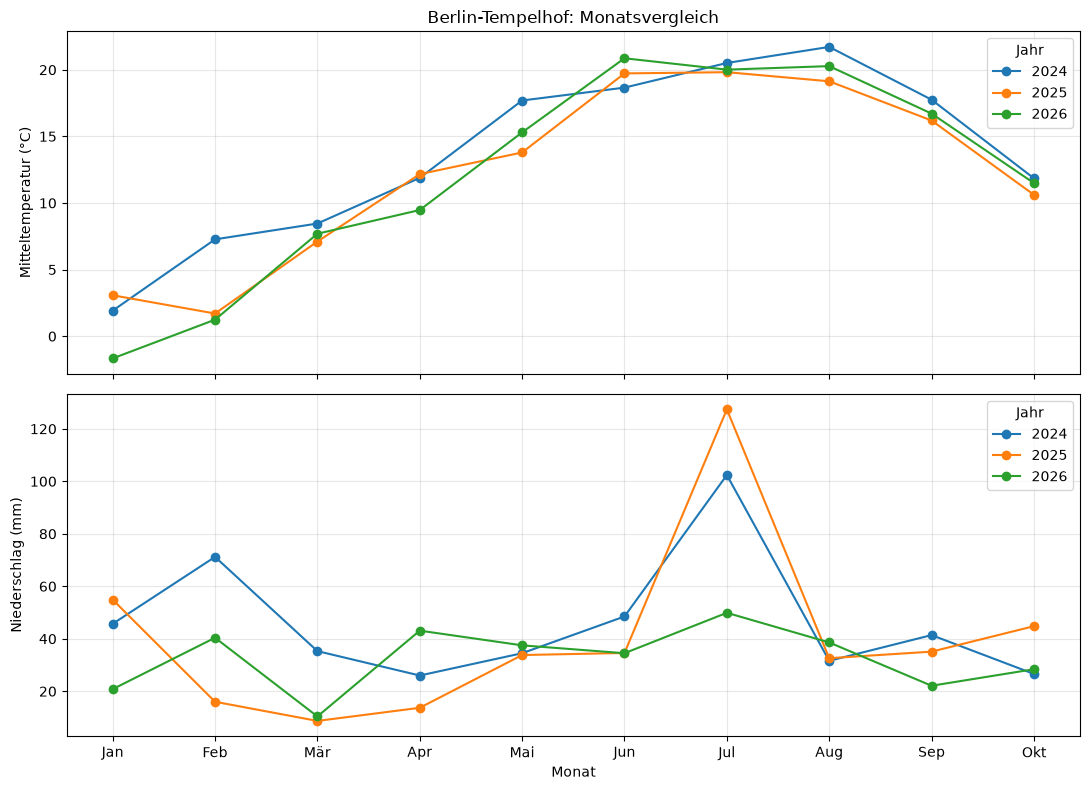

Monatsdiagramme zeigen Januar bis Okt.


In [9]:
vollstaendige_monate = (
    letzter_2026_tag.month
    if letzter_2026_tag.day == monthrange(letzter_2026_tag.year, letzter_2026_tag.month)[1]
    else letzter_2026_tag.month - 1
)
monatsmittel = defaultdict(list)
monatssummen = defaultdict(float)

for eintrag in daten:
    datum = eintrag["datum"]
    if datum.month > vollstaendige_monate:
        continue
    if eintrag["mittel"] is not None:
        monatsmittel[(datum.year, datum.month)].append(eintrag["mittel"])
    if eintrag["niederschlag"] is not None:
        monatssummen[(datum.year, datum.month)] += eintrag["niederschlag"]

monate = list(range(1, vollstaendige_monate + 1))
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
fig, (temperatur_ax, regen_ax) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for jahr in jahre:
    temperatur_ax.plot(
        monate,
        [mean(monatsmittel[(jahr, monat)]) for monat in monate],
        marker="o",
        label=str(jahr),
    )
    regen_ax.plot(
        monate,
        [monatssummen[(jahr, monat)] for monat in monate],
        marker="o",
        label=str(jahr),
    )

temperatur_ax.set_title(f"{station_name}: Monatsvergleich")
temperatur_ax.set_ylabel("Mitteltemperatur (°C)")
temperatur_ax.grid(True, alpha=0.3)
temperatur_ax.legend(title="Jahr")
regen_ax.set_ylabel("Niederschlag (mm)")
regen_ax.set_xlabel("Monat")
regen_ax.set_xticks(monate, [monatsnamen[monat - 1] for monat in monate])
regen_ax.grid(True, alpha=0.3)
regen_ax.legend(title="Jahr")
fig.tight_layout()
plt.show()

print(f"Monatsdiagramme zeigen Januar bis {monatsnamen[vollstaendige_monate - 1]}.")

## 4. Weiter untersuchen

- Ändere die Stationsnummer in der Konfiguration und prüfe eine andere DWD-Station.
- Vergleiche die Monatsmitteltemperatur mit den Niederschlagssummen: Fallen besonders warme Monate auch trocken aus?
- Zähle für den Vergleichszeitraum Tage mit einem Tagesmaximum über 30 °C.

Die Station Berlin-Tempelhof steht stellvertretend für ihren Messort. Ihre Werte können von anderen Berliner Stationen abweichen. 2026 ist ein laufendes Jahr; die aktuellen DWD-Daten können sich noch ergänzen.